# asymmetric_division

PhysiCell's `PhysiCell/sample_projects/asymmetric_division` as a **self-contained notebook**. The model below is Python,
generated from that project's XML and rules CSV; nothing here reads a PhysiCell
file, builds an executable or parses an output folder.

| | |
|---|---|
| domain | 50 x 50 x 1 voxels, dx=20 um, 2D |
| substrates | substrate |
| cell types | stem, progenitor_1, progenitor_2 |
| rules | 3 (3 runnable here) |
| initial cells | 1, from `data/asymmetric_division_cells.csv` |

**Sections 3 to 7 are the point of the library**: each one is something the
XML-and-executable workflow cannot do at all, or can only do by editing C++,
recompiling and re-running from t=0.


In [1]:
import pathlib
import numpy as np, matplotlib.pyplot as plt
import pyphysicell as pc
from pyphysicell import viz

# the data this notebook needs sits next to it
DATA = next(p for p in (pathlib.Path('data'), pathlib.Path('notebooks/data'))
            if p.exists())
print('kernels:', pc.BACKEND, '|', pc.MAX_THREADS, 'threads', '| data:', DATA)

kernels: std::thread | 2 threads | data: data


## 1. The model is an object

Not a document to be parsed at start-up: a value you can read, edit, copy, hash
and generate. Everything below came from the project's XML.

In [2]:
# Generated by pyphysicell.codegen from PhysiCell/sample_projects/asymmetric_division.
# Values are PhysiCell's: minutes, microns, and each substrate's own units.


model = pc.Model(name="asymmetric_division")
model.domain = pc.Domain(x_min=-500.0, x_max=500.0, y_min=-500.0, y_max=500.0, z_min=-10.0, z_max=10.0, dx=20.0, dy=20.0, dz=20.0, use_2D=True)
model.time = pc.Time(dt_diffusion=0.01, dt_mechanics=0.1, dt_phenotype=6.0, max_time=1440.0, time_units="min", space_units="micron")
model.random_seed = 0
model.virtual_wall = True
model.omp_num_threads = 6
model.calculate_gradients = True
model.track_internalized_substrates = True
model.disable_automated_spring_adhesions = False
model.legacy_division_orientation = False
model.save = pc.SaveOptions(folder="output", full_interval=6.0, full_enabled=True, svg_interval=6.0, svg_enabled=True)

# --- substrates --------------------------------------------------------------
model.substrates = [
    pc.Substrate(
        "substrate",
        diffusion_coefficient=100000.0,
        decay_rate=10.0,
        initial_condition=0.0,
        dirichlet_enabled=False, dirichlet_value=0.0,
        dirichlet_faces={"xmax": (False, 0.0), "xmin": (False, 0.0), "ymax": (False, 0.0), "ymin": (False, 0.0), "zmax": (False, 0.0), "zmin": (False, 0.0)},
    ),
]

# --- cell types --------------------------------------------------------------
ct0 = pc.CellType("stem", ID=0)
ct0.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0006944444444444445},
         fixed_duration={(0, 0): False},
         asymmetric_division={"stem": 0.0, "progenitor_1": 1.0, "progenitor_2": 0.0})
ct0.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct0.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct0.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"stem": 1.0, "progenitor_1": 1.0, "progenitor_2": 1.0})
ct0.motility = pc.Motility(speed=1.0, persistence_time=1.0, migration_bias=0.5, enabled=False, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="substrate", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"substrate": 0.0})
ct0.secretion = {
    "substrate": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct0.custom_data = {"sample": 1.0}
ct0.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    attack_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    fusion_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    transformation_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    immunogenicities={})
ct0.custom_conserved = {"sample": False}

ct1 = pc.CellType("progenitor_1", ID=1)
ct1.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct1.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 515.9958720330237},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 1.1111111111111111e-10, 1: 86399.80646443352},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.000216667,
              calcification_rate=7e-05,
              relative_rupture_volume=2.0)}
ct1.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct1.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"stem": 1.0, "progenitor_1": 1.0, "progenitor_2": 1.0})
ct1.motility = pc.Motility(speed=1.0, persistence_time=1.0, migration_bias=0.0, enabled=False, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="substrate", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"substrate": 0.0})
ct1.secretion = {
    "substrate": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct1.custom_data = {"sample": 0.0}
ct1.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    attack_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    fusion_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    transformation_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    immunogenicities={})
ct1.custom_conserved = {"sample": False}

ct2 = pc.CellType("progenitor_2", ID=2)
ct2.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct2.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 515.9958720330237},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 1.1111111111111111e-10, 1: 86399.80646443352},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.000216667,
              calcification_rate=7e-05,
              relative_rupture_volume=2.0)}
ct2.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct2.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"stem": 1.0, "progenitor_1": 1.0, "progenitor_2": 1.0})
ct2.motility = pc.Motility(speed=1.0, persistence_time=1.0, migration_bias=0.0, enabled=False, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="substrate", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"substrate": 0.0})
ct2.secretion = {
    "substrate": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct2.custom_data = {"sample": 0.0}
ct2.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    attack_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    fusion_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    transformation_rates={"stem": 0.0, "progenitor_1": 0.0, "progenitor_2": 0.0},
    immunogenicities={})
ct2.custom_conserved = {"sample": False}

model.cell_types = [ct0, ct1, ct2]

model.user_parameters = {"number_of_cells": 0}

# --- rules (cell behavior hypothesis grammar) ---------------------------------
model.rules = [
    pc.Rule("stem", "contact with progenitor_1", "decreases", "asymmetric division to progenitor_1", max_response=0.0, half_max=3.0, hill_power=4.0, apply_to_dead=False),
    pc.Rule("stem", "contact with progenitor_1", "increases", "asymmetric division to progenitor_2", max_response=1.0, half_max=3.0, hill_power=4.0, apply_to_dead=False),
    pc.Rule("stem", "volume", "increases", "cycle entry", max_response=0.17, half_max=1200.0, hill_power=8.0, apply_to_dead=False),
]

# --- initial conditions ------------------------------------------------------
# Initial conditions live beside this notebook (1 stem).
CELLS = DATA / 'asymmetric_division_cells.csv'
model.initial_cells = pc.read_cells_csv(CELLS, model.cell_type_names)
print(f'{len(model.initial_cells)} cells from {CELLS.name}')

1 cells from asymmetric_division_cells.csv


In [3]:
print(model.summary())
print('content hash:', model.hash, '-- changes with any edit, so runs are traceable')

model 'asymmetric_division'  [bdebf72b78fb]
  domain     50 x 50 x 1 voxels, dx=20 um, 2D
  time       dt_diff=0.01 dt_mech=0.1 dt_pheno=6  max_time=1440 min
  substrates substrate
  cell types stem, progenitor_1, progenitor_2
  rules      3
  initial    1 cells
content hash: bdebf72b78fb -- changes with any edit, so runs are traceable


## 2. Answers before you simulate

These cost milliseconds and need no run at all. `check()` is dimensional analysis
of the model as written; the cycle duration is closed-form from the phase graph;
a rule's response curve is a pure function of its signal.

In [4]:
print(pc.check(model))

check: 'asymmetric_division' [bdebf72b78fb]
  [marginal] substrate                  L=sqrt(D/lambda)=   100.0 um =   5.0 dx
  [info    ] stem                       cycle mean duration 24.0 h (from the phase graph, no simulation)
  [info    ] progenitor_1               does not cycle on its own (rate 0; a rule may drive it)
  [info    ] progenitor_2               does not cycle on its own (rate 0; a rule may drive it)
  [info    ] mesh 50x50x1 = 2500 voxels, 0.0 MB of field per saved snapshot
  [info    ] 144000 diffusion steps to reach max_time=1440 min


In [5]:
for ct in model.cell_types:
    d = ct.cycle.mean_duration()
    print(f'{ct.name:<28} cycle {d/60:8.1f} h' if np.isfinite(d)
          else f'{ct.name:<28} does not cycle on its own')

stem                         cycle     24.0 h
progenitor_1                 does not cycle on its own
progenitor_2                 does not cycle on its own


In stem cells, contact with progenitor_1 decreases asymmetric division to progenitor_1 towards 0 with half-max 3 and Hill power 4.
In stem cells, contact with progenitor_1 increases asymmetric division to progenitor_2 towards 1 with half-max 3 and Hill power 4.
In stem cells, volume increases cycle entry towards 0.17 with half-max 1200 and Hill power 8.


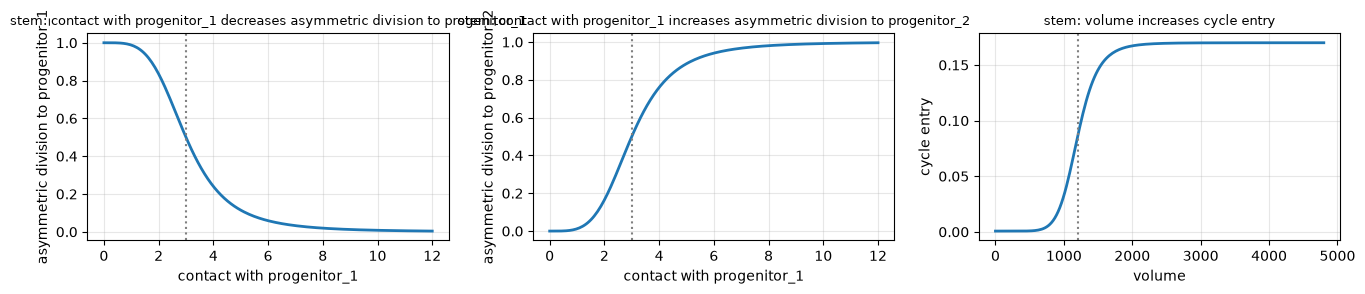

In [6]:
d = pc.Dictionary(model)
shown = [r for r in model.rules if d.supports_signal(r.signal)
         and d.supports_behavior(r.behavior)][:3]
fig, axes = plt.subplots(1, len(shown), figsize=(4.5 * len(shown), 3))
for ax, r in zip(np.atleast_1d(axes), shown):
    viz.plot_rule(r, d.base_behavior(r.cell_type, r.behavior), ax=ax)
    print(r.english())
plt.tight_layout()

## 3. Run it, and keep the simulation

`sim` stays alive afterwards: its cells and fields are NumPy arrays you can read
and change, and the run can be continued. The executable exits and leaves files.

This demo covers 1237.35 min. One turn of this model's fastest cycle is 1440 min and its own config asks for 1440 min, so what follows is a smoke test of the machinery, not a result: at this window the population cannot divide.

In [7]:
sim = pc.Simulation(model, seed=model.random_seed)
if not sim.cells.n:
    print(pc.initial.apply(sim))
scalars = sim.run(until=1237.35, record_every=103.112)
print(sim, f'| {sim.wall_time:.1f} s')
sim.dataframe().head(3)

<Simulation 'asymmetric_division' t=1237.3 min cells=15 backend=std::thread:2> | 9.9 s


,ID,x,y,z,type,volume,radius,phase,dead,pressure,cell_type
0,0,8.590482,-12.530610,0.0,0,688.820288,5.478636,0,False,1.028193,stem
1,1,24.595564,2.999000,0.0,1,2488.629950,8.406668,0,False,0.298771,progenitor_1
2,2,-25.678517,12.450934,0.0,1,2485.793190,8.403473,0,False,0.222866,progenitor_1


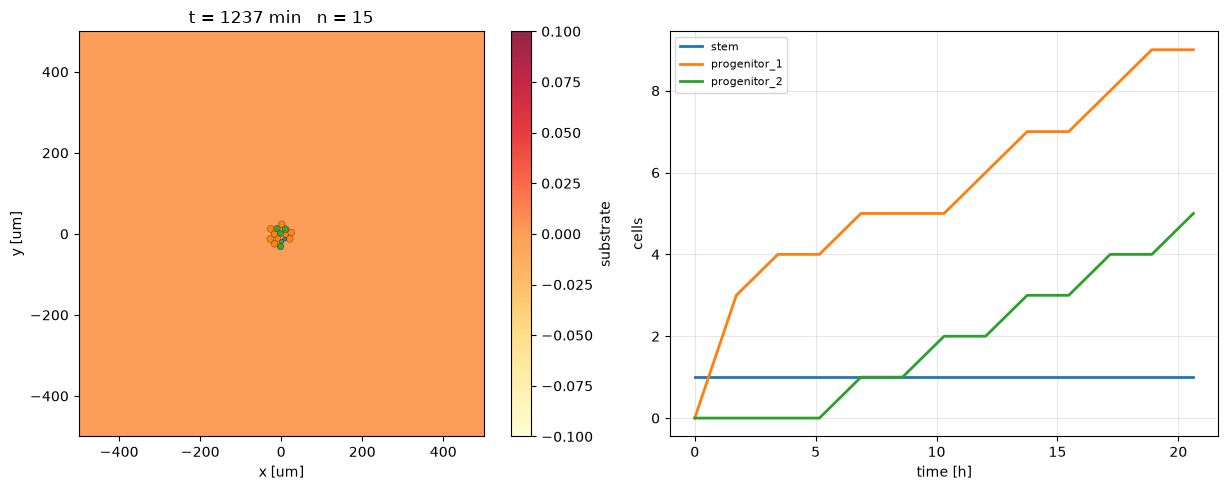

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
viz.plot_cells(sim, substrate='substrate', ax=axes[0])
viz.plot_populations(scalars, ax=axes[1])
plt.tight_layout()

## 4. Steer it while it runs

Change the state mid-run and carry on from where you are. In the file workflow
this is a new XML and a new run from t=0, or custom C++ and a recompile.

mean substrate 0 -> 0


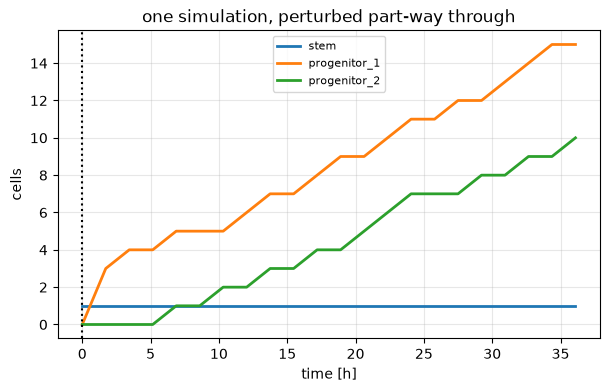

In [9]:
before = sim.microenvironment['substrate'].mean()
sim.microenvironment.density[..., 0] = 0.0      # remove substrate everywhere
sim.run(until=sim.t + 928.01, record_every=103.112)
print(f'mean substrate {before:.3g} -> {sim.microenvironment['substrate'].mean():.3g}')
viz.plot_populations(sim.scalars)
plt.axvline(sim.scalars.times[0] / 60, ls=':', c='k')
plt.title('one simulation, perturbed part-way through');

## 5. Two futures from one state

`branch()` is a deepcopy of the whole simulation, because all of the state is
Python. PhysiCell keeps its state in process globals, so a second simulation in
the same process is impossible there and a counterfactual means re-running from
the beginning with a different input file.

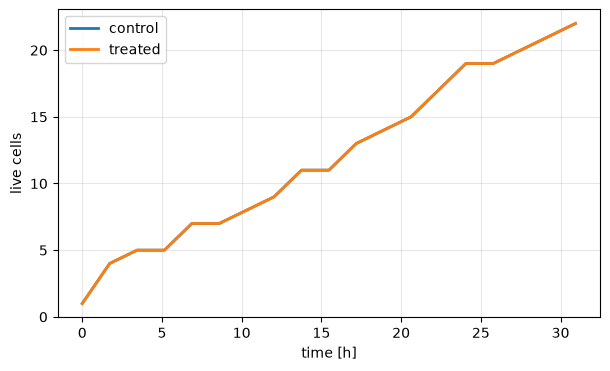

In [10]:
base = pc.Simulation(model, seed=model.random_seed)
if not base.cells.n:
    pc.initial.apply(base)
base.run(until=928.01, record_every=103.112)

control = base.branch()
treated = base.branch()
treated.microenvironment.density[..., 0] *= 0.1   # 90% knock-down
control.run(until=control.t + 928.01, record_every=103.112)
treated.run(until=treated.t + 928.01, record_every=103.112)

fig, ax = plt.subplots(figsize=(7, 4))
for name, s in (('control', control.scalars), ('treated', treated.scalars)):
    total = np.sum([v for v in s.counts.values()], axis=0)
    ax.plot(np.asarray(s.times) / 60, total, lw=2, label=name)
ax.set_xlabel('time [h]'); ax.set_ylabel('live cells'); ax.legend(); ax.grid(alpha=0.3);

## 6. Logic the rules grammar cannot express

A CBHG rule is a Hill function of one cell's own signals: it cannot see where a
cell is, or how it ranks against the rest of the population. A hook is arbitrary
Python over the whole population, called once per phenotype step on arrays, so
both become possible -- and still no C++.

In [11]:
probe = pc.Simulation(model, seed=model.random_seed)
if not probe.cells.n:
    pc.initial.apply(probe)
log = []

@probe.hook('phenotype', cell_type='stem')
def spatial_and_population_relative(ctx):
    p = ctx.signals['pressure']
    crowded = p >= np.quantile(p, 0.9) if ctx.n > 1 else np.zeros(ctx.n, bool)
    left = ctx.position[:, 0] < 0
    # population-relative: the most crowded tenth stops cycling
    ctx.behaviors['cycle entry'] = np.where(crowded, 0.0,
                                            ctx.behaviors['cycle entry'])
    # spatial: cells in the left half of the domain stop migrating
    ctx.behaviors['migration speed'] = np.where(left, 0.0,
                                                ctx.behaviors['migration speed'])
    log.append((ctx.t, int(crowded.sum()), float(left.mean())))

probe.run(until=928.01, record_every=103.112)
c = probe.cells
mine = c.view('type_idx') == probe.type_index['stem']
left = mine & (c.view('position')[:, 0] < 0)
right = mine & (c.view('position')[:, 0] >= 0)
print(f'hook fired {len(log)} times, one call per phenotype step for all {mine.sum()} cells')
print(f"  mean migration speed   left {c.view('motility_speed')[left].mean():.3f}   right {c.view('motility_speed')[right].mean():.3f}")
print(f"  mean cycle entry rate  crowded decile is held at 0; population mean {c.view('cycle_entry_rate')[mine].mean():.3e}")

hook fired 155 times, one call per phenotype step for all 1 cells
  mean migration speed   left nan   right 0.000
  mean cycle entry rate  crowded decile is held at 0; population mean 2.432e-02


/var/folders/53/v81y030d3y51nbzr_58b82fw0000gn/T/ipykernel_71745/4143277081.py:25: RuntimeWarning: Mean of empty slice
  print(f"  mean migration speed   left {c.view('motility_speed')[left].mean():.3f}   right {c.view('motility_speed')[right].mean():.3f}")
/Users/denphi/Documents/Github/pyphysicell/pyphysicell/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


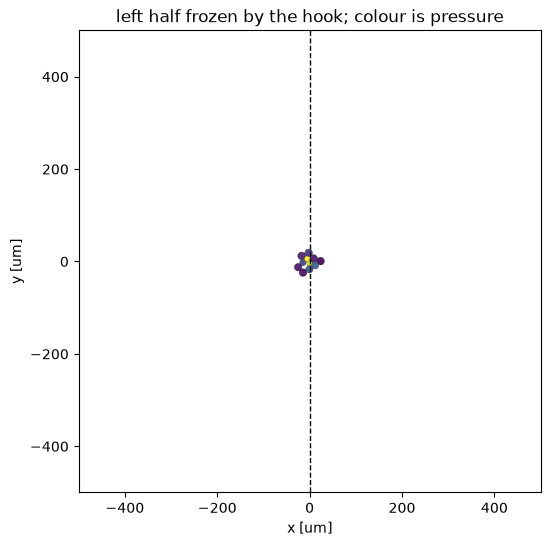

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
viz.plot_cells(probe, color_by='pressure', ax=ax)
ax.axvline(0, ls='--', c='k', lw=1)
ax.set_title('left half frozen by the hook; colour is pressure');

## 7. A sweep in one process

Varying the cycle transition rate of stem, with replicates. No files, no subprocesses, no recompilation --
the models and the simulations are objects, so N of them are just N objects.

*That parameter was not chosen by hand.* The generator screened every knob this
model exposes -- rule half-maxes and saturated responses, cycle and death rates,
migration speed, substrate decay -- at half and double its published value, and
kept the one that moved an outcome most (18% spread at x4). Most knobs
in a
published model move nothing at its own parameters, which is itself worth
knowing before you spend a cluster on a sweep.

In [13]:
def change(m, value):
    m.cell_type('stem').cycle.transition_rates[(0, 0)] = value

df, runs = pc.sweep(model, change, [0.0001736, 0.0006944, 0.002778], until=928.01,
                    replicates=2, progress=True)
df[['value', 'replicate', 'cells', 'births', 'deaths', 'spread_um',
    'mean_pressure', 'wall_s']]

     0.0001736  rep 0  ->      11 cells (8.3 s)


     0.0001736  rep 1  ->      11 cells (8.7 s)


     0.0006944  rep 0  ->      13 cells (8.2 s)


     0.0006944  rep 1  ->      12 cells (8.8 s)


      0.002778  rep 0  ->      13 cells (8.9 s)


      0.002778  rep 1  ->      12 cells (8.8 s)


,value,replicate,cells,births,deaths,spread_um,mean_pressure,wall_s
0,0.000174,0,11,10,0,18.28,0.3858,8.27
1,0.000174,1,11,10,0,19.62,0.3191,8.66
2,0.000694,0,13,12,0,20.15,0.3643,8.22
3,0.000694,1,12,11,0,19.47,0.3820,8.79
4,0.002778,0,13,12,0,20.13,0.3967,8.93
5,0.002778,1,12,11,0,20.52,0.3115,8.76


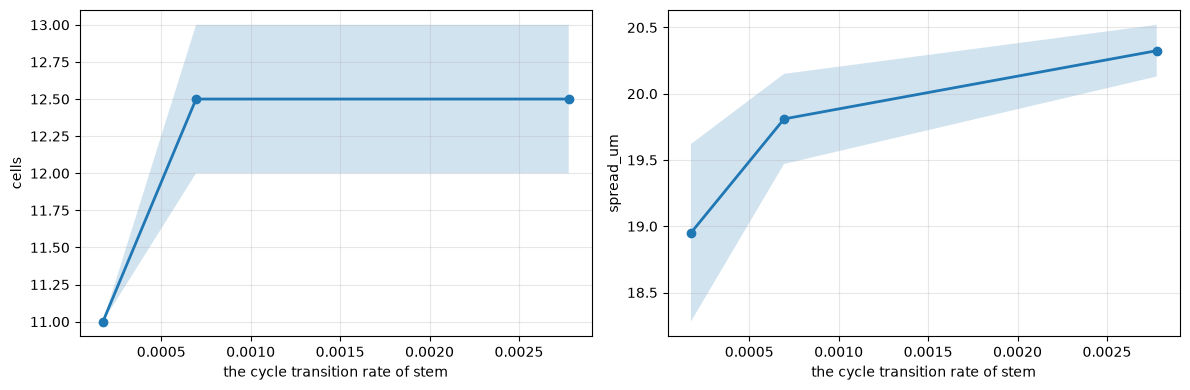

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pc.plot_sweep(df, 'cells', ax=axes[0], label='live cells')
pc.plot_sweep(df, 'spread_um', ax=axes[1], label='spread (RMS radius)')
axes[0].set_xlabel('the cycle transition rate of stem'); axes[1].set_xlabel('the cycle transition rate of stem')
plt.tight_layout()

## 8. Stop when something happens

A question like *when* does this model cross a level is a stopping condition
here, and a post-hoc search through saved snapshots otherwise.

The level is read off the run in section 3 rather than guessed, so the condition
is an event this model really reaches. An earlier version of this notebook picked
a threshold a priori and ran to its limit in 19 of 37 projects, demonstrating
nothing.

In [15]:
import numpy as np
h = sim.scalars
t = np.asarray(h.times, dtype=float)
# sections 4-6 steered this same sim, so calibrate on the untouched part
keep = t <= 1237.35
t = t[keep]
series = {}
if h.counts:
    series['live cells'] = np.asarray([sum(v) for v in zip(*h.counts.values())],
                                      dtype=float)[keep]
series['dead cells'] = np.asarray(h.dead, dtype=float)[keep]
series['cumulative births'] = np.asarray(h.births, dtype=float)[keep]
series['cumulative deaths'] = np.asarray(h.deaths, dtype=float)[keep]
for _s, _v in h.mean_substrate.items():
    series[f'mean {_s}'] = np.asarray(_v, dtype=float)[keep]

def moved(v):
    scale = max(float(np.abs(v).max()), 1e-12)
    return max(abs(v[-1] - v[0]), v.max() - v.min()) / scale

name, y = max(series.items(), key=lambda kv: moved(kv[1]))
y0, lo, hi, end = float(y[0]), float(y.min()), float(y.max()), float(y[-1])
if end != y0:                      # 60% of the way to where it ended
    rising, level = end > y0, y0 + 0.6 * (end - y0)
else:                              # it came back: aim at the far extreme
    rising = (hi - y0) >= (y0 - lo)
    level = y0 + 0.6 * ((hi - y0) if rising else (lo - y0))
live = moved(y) > 0
print(f'{sum(moved(v) > 0 for v in series.values())} of {len(series)} recorded observables moved')
if live:
    crossed = t[np.argmax((y >= level) if rising else (y <= level))]
    print(f'watching {name}: the baseline crossed {level:.4g} at t = {crossed:.1f} min')
else:
    print('nothing this model records changes over the demo window')

2 of 5 recorded observables moved
watching cumulative births: the baseline crossed 8.4 at t = 824.9 min


In [16]:
readers = {'live cells': lambda s: float((s.cells.view('dead') == 0).sum()),
           'dead cells': lambda s: float((s.cells.view('dead') == 1).sum()),
           'cumulative births': lambda s: float(s._births),
           'cumulative deaths': lambda s: float(s._deaths)}
for _s in model.substrate_names:
    readers[f'mean {_s}'] = (lambda n: lambda s: float(s.microenvironment[n].mean()))(_s)
read = readers[name]

watch = pc.Simulation(model, seed=model.random_seed)
if not watch.cells.n:
    pc.initial.apply(watch)
limit = 4949.4
watch.run(until=limit, record_every=103.112,
          stop_when=(lambda s: (read(s) >= level) if rising else (read(s) <= level))
                    if live else None)
print(f'stopped at t = {watch.t:.1f} min of a {limit:.0f} min limit, {name} = {read(watch):.4g}')
if live:
    assert watch.t < limit, 'the stopping condition never fired'

stopped at t = 762.0 min of a 4949 min limit, cumulative births = 9
